## Courier Workload and Movement in a Selected Delivery Area (Flag 2)

### Dataset Overview
The main table contains delivery-order event times and trajectory-anchored receipt and destination coordinates for courier-days operating in a selected delivery area. Reference tables provide courier-day identities and GPS trajectory points.

The notebook exposes a primary table and a supporting table (`trajectory_points.csv`).

Goal: Analyze the couriers serving the selected area during the observed time window and summarize their workload, movement, and delivery-state patterns.

Role: Last-mile delivery operations analyst


Category: Courier and Order Insight

### Your Objective
Use the provided tables and visual evidence to answer the questions below and summarize the observed trajectory patterns.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, SVG, display

## Load Dataset

The primary table is loaded into `df`; when available, the supporting trajectory or driver table is loaded into `user_df`.

In [ ]:
dataset_path = "orders.csv"
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "trajectory_points.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: How do the number and timing of observed order events differ across courier-days in the selected area?

#### Analysis action

Compare courier-day workload and event timing together before characterizing the selected area as uniform or heterogeneous.

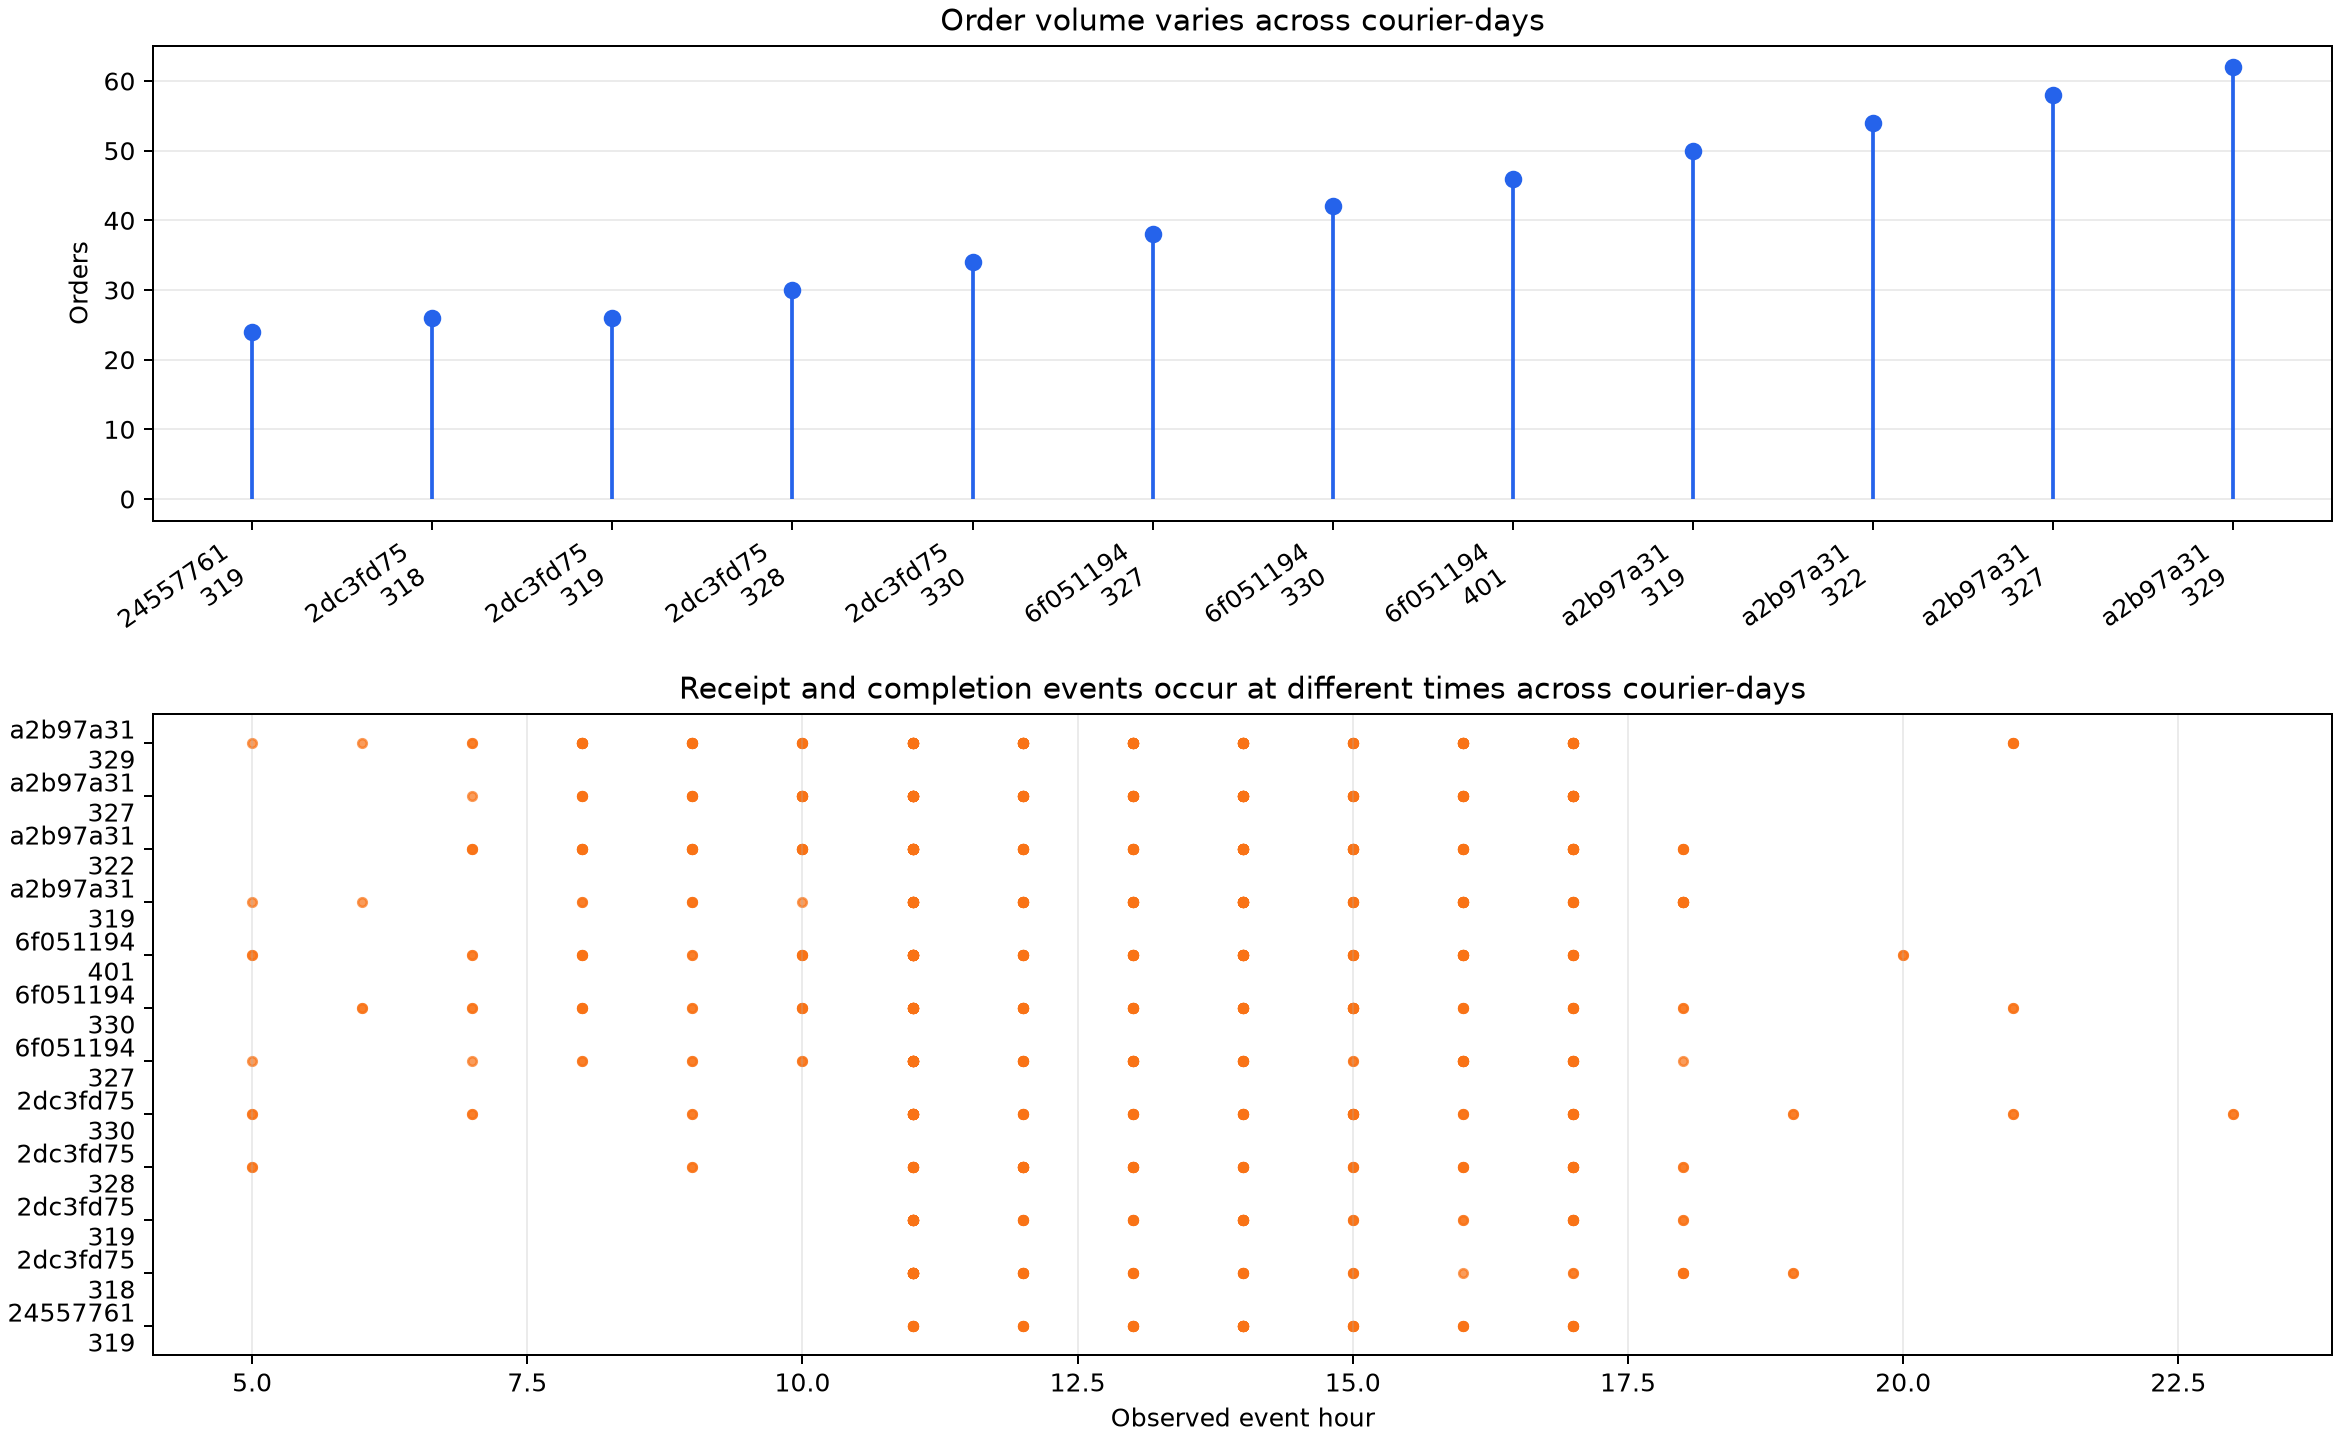

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
d = df.copy(); d['receipt_hour'] = pd.to_datetime(d['receipt_time']).dt.hour; d['sign_hour'] = pd.to_datetime(d['sign_time']).dt.hour
g = d.groupby(['case_courier_id','ds'])
labels = [f'{c[-8:]}\n{ds}' for c, ds in g.size().index]
fig, ax = plt.subplots(2, 1, figsize=(13, 8))
counts = g.size().to_numpy(); x = np.arange(len(labels)); ax[0].stem(x, counts, basefmt=' '); ax[0].set_xticks(x, labels, rotation=35); ax[0].set_ylabel('Orders')
for i, (_, q) in enumerate(g):
 hours = pd.concat([q['receipt_hour'], q['sign_hour']]).dropna(); ax[1].scatter(hours, [i] * len(hours), s=12)
ax[1].set_yticks(x, labels); ax[1].set_xlabel('Observed event hour'); plt.tight_layout(); plt.show()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/courier_order_count_and_timing.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "comparative",
  "insight": "The selected area contains substantial variation in the number and timing of orders handled by different couriers.",
  "insight_value": {
    "comparison": "Courier-days differ in both observed order counts and the time span of their order events."
  },
  "plot": {
    "plot_type": "order_count_lollipop_and_event_raster",
    "title": "Courier-Day Order Volume and Event Timing",
    "file": "visualizations/courier_order_count_and_timing.png",
    "description": "The upper panel uses lollipop marks for order counts; the lower event raster shows the observed receipt and completion times for every courier-day."
  },
  "question": "How do the number and timing of observed order events differ across courier-days in the selected area?",
  "actionable_insight": "Compare courier-day workload and event timing together before characterizing the selected area as uniform or heterogeneous.",
  "code": "import pandas as pd\nimport matplotlib.pyplot as plt\nimport numpy as np\nd = df.copy(); d['receipt_hour'] = pd.to_datetime(d['receipt_time']).dt.hour; d['sign_hour'] = pd.to_datetime(d['sign_time']).dt.hour\ng = d.groupby(['case_courier_id','ds'])\nlabels = [f'{c[-8:]}\\n{ds}' for c, ds in g.size().index]\nfig, ax = plt.subplots(2, 1, figsize=(13, 8))\ncounts = g.size().to_numpy(); x = np.arange(len(labels)); ax[0].stem(x, counts, basefmt=' '); ax[0].set_xticks(x, labels, rotation=35); ax[0].set_ylabel('Orders')\nfor i, (_, q) in enumerate(g):\n hours = pd.concat([q['receipt_hour'], q['sign_hour']]).dropna(); ax[1].scatter(hours, [i] * len(hours), s=12)\nax[1].set_yticks(x, labels); ax[1].set_xlabel('Observed event hour'); plt.tight_layout(); plt.show()",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "courier_id",
    "receipt_time",
    "completion_time",
    "task_id"
  ]
}

### **Question 2**: How do observed courier speeds differ across spatial parts of the selected area?

#### Analysis action

Use the spatial speed pattern to compare areas, while treating it as an observed movement difference rather than an explanation of its cause.

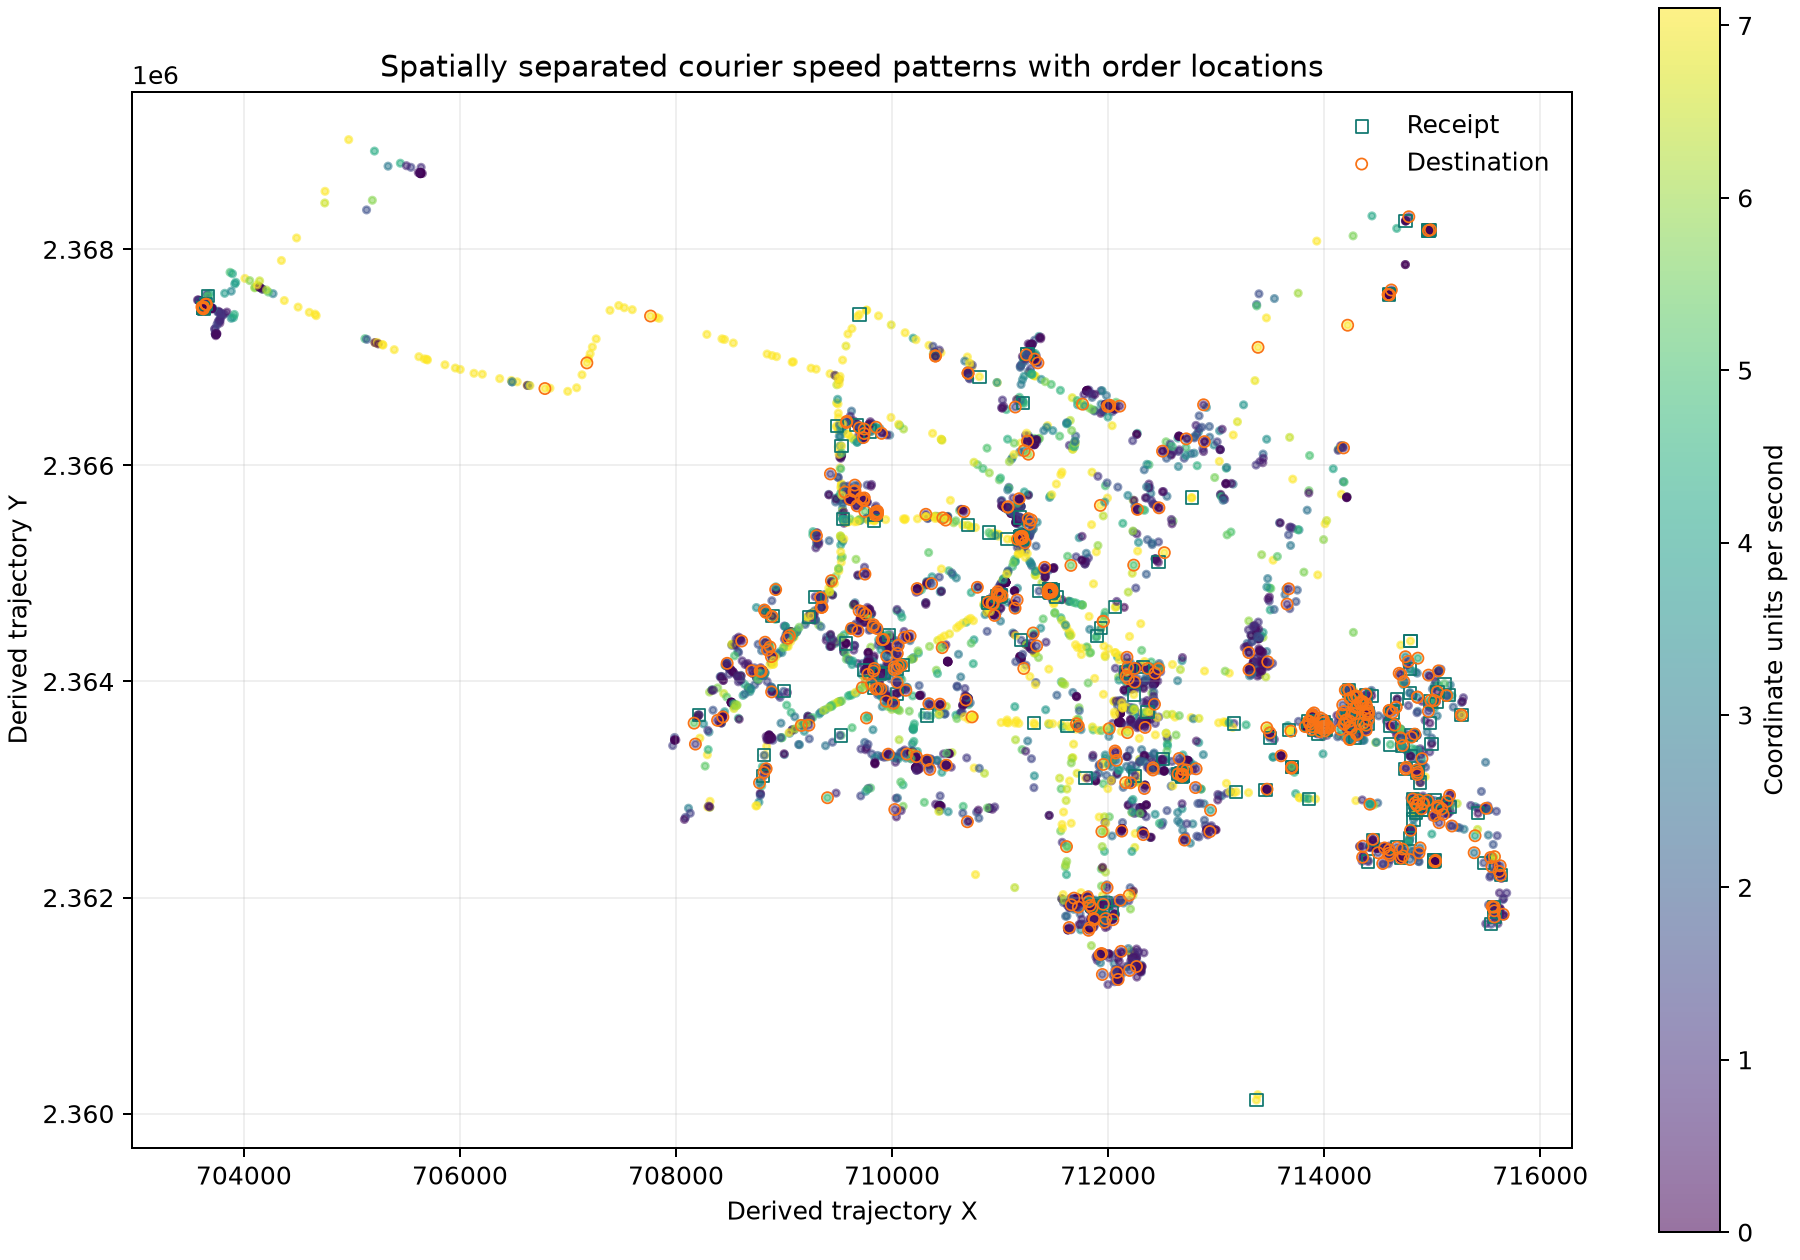

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
t = user_df.copy(); t['time'] = pd.to_datetime(t['gps_time']); t = t.sort_values(['case_courier_id','ds','time']); keys=['case_courier_id','ds']; t['speed'] = np.hypot(t.groupby(keys)['lng'].diff(), t.groupby(keys)['lat'].diff()) / t.groupby(keys)['time'].diff().dt.total_seconds();
plt.figure(figsize=(10,7)); plt.scatter(t['lng'], t['lat'], c=t['speed'], s=7, cmap='viridis'); plt.scatter(df['receipt_lng'], df['receipt_lat'], facecolors='none', edgecolors='teal', marker='s', label='Receipt'); plt.scatter(df['poi_lng'], df['poi_lat'], facecolors='none', edgecolors='darkorange', label='Destination'); plt.colorbar(label='Coordinate units per second'); plt.axis('equal'); plt.legend(); plt.show()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/spatial_speed_and_events.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: High (5 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "comparative",
  "insight": "Spatially separated parts of the selected area show different observed movement-speed patterns after comparing the event and trajectory evidence.",
  "insight_value": {
    "comparison": "The spatial pattern of observed trajectory speed is not uniform across the selected area."
  },
  "plot": {
    "plot_type": "spatial_speed_event_map",
    "title": "Spatial Speed Patterns and Order Locations",
    "file": "visualizations/spatial_speed_and_events.png",
    "description": "GPS observations are colored continuously by local speed, while receipt and destination locations are overlaid with different outlines so the spatial speed contrast can be inspected together with order activity."
  },
  "question": "How do observed courier speeds differ across spatial parts of the selected area?",
  "actionable_insight": "Use the spatial speed pattern to compare areas, while treating it as an observed movement difference rather than an explanation of its cause.",
  "code": "import pandas as pd\nimport numpy as np\nimport matplotlib.pyplot as plt\nt = user_df.copy(); t['time'] = pd.to_datetime(t['gps_time']); t = t.sort_values(['case_courier_id','ds','time']); keys=['case_courier_id','ds']; t['speed'] = np.hypot(t.groupby(keys)['lng'].diff(), t.groupby(keys)['lat'].diff()) / t.groupby(keys)['time'].diff().dt.total_seconds();\nplt.figure(figsize=(10,7)); plt.scatter(t['lng'], t['lat'], c=t['speed'], s=7, cmap='viridis'); plt.scatter(df['receipt_lng'], df['receipt_lat'], facecolors='none', edgecolors='teal', marker='s', label='Receipt'); plt.scatter(df['poi_lng'], df['poi_lat'], facecolors='none', edgecolors='darkorange', label='Destination'); plt.colorbar(label='Coordinate units per second'); plt.axis('equal'); plt.legend(); plt.show()",
  "difficulty_level": 5,
  "difficulty_label": "high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_time",
    "gps_position",
    "courier_id",
    "receipt_position",
    "destination_position"
  ]
}

### **Question 3**: How does the observed workload of individual couriers change over the selected interval, particularly after noon?

#### Analysis action

Compare the per-courier workload trajectories with the area-level event balance to distinguish changes shared by most couriers from changes specific to individual couriers.

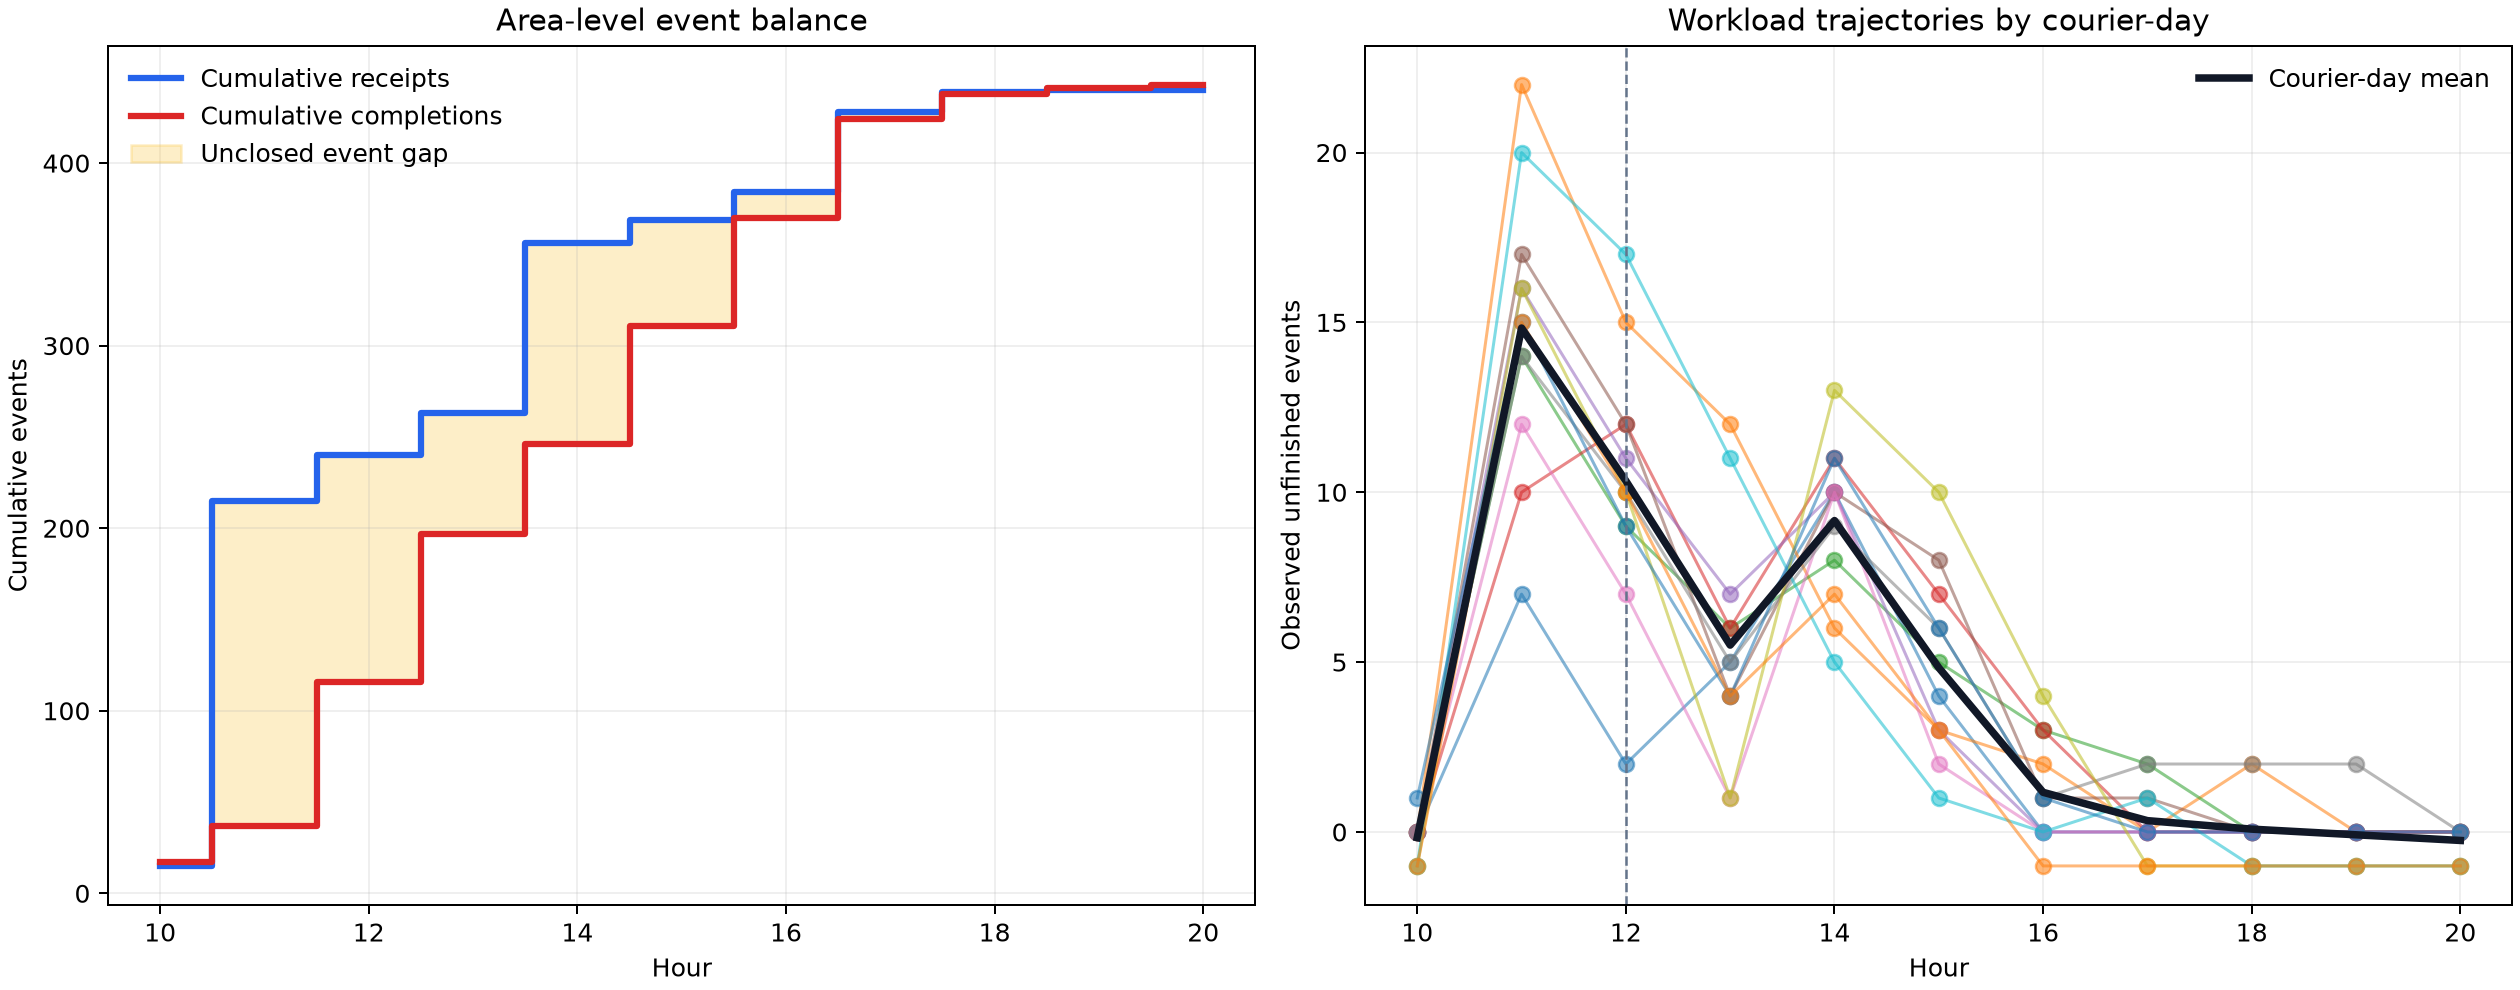

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
d = df.copy(); d['receipt_hour'] = pd.to_datetime(d['receipt_time']).dt.hour; d['sign_hour'] = pd.to_datetime(d['sign_time']).dt.hour; hours = np.arange(10, 21)
fig, ax = plt.subplots(1,2,figsize=(14,5))
accepted = [d['receipt_hour'].eq(h).sum() for h in hours]; completed = [d['sign_hour'].eq(h).sum() for h in hours]; ax[0].step(hours, np.cumsum(accepted), where='mid', label='Cumulative receipts'); ax[0].step(hours, np.cumsum(completed), where='mid', label='Cumulative completions'); ax[0].legend(); ax[0].set_title('Area-level event balance')
for _, q in d.groupby(['case_courier_id','ds']):
 a=q['receipt_hour'].value_counts(); c=q['sign_hour'].value_counts(); workload=[sum(a.get(k,0)-c.get(k,0) for k in hours if k<=h) for h in hours]; ax[1].plot(hours, workload, alpha=.5)
ax[1].set_title('Workload trajectories by courier-day'); ax[1].set_xlabel('Hour'); plt.tight_layout(); plt.show()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/event_balance_workload.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "diagnostic",
  "insight": "The area-level balance between newly accepted and completed orders changes over the selected interval. For most couriers, the observed workload generally declines after noon, with fewer orders remaining in progress per courier as the day progresses.",
  "insight_value": {
    "comparison": "The area-level event balance changes over time, and the observed workload generally declines after noon for most couriers."
  },
  "plot": {
    "plot_type": "event_balance_and_workload_paths",
    "title": "Area-Level Event Balance and Courier Workload",
    "file": "visualizations/event_balance_workload.png",
    "description": "The left panel compares cumulative receipt and completion events; the right panel shows each courier-day workload trajectory together with the cross-courier mean."
  },
  "question": "How does the observed workload of individual couriers change over the selected interval, particularly after noon?",
  "actionable_insight": "Compare the per-courier workload trajectories with the area-level event balance to distinguish changes shared by most couriers from changes specific to individual couriers.",
  "code": "import pandas as pd\nimport numpy as np\nimport matplotlib.pyplot as plt\nd = df.copy(); d['receipt_hour'] = pd.to_datetime(d['receipt_time']).dt.hour; d['sign_hour'] = pd.to_datetime(d['sign_time']).dt.hour; hours = np.arange(10, 21)\nfig, ax = plt.subplots(1,2,figsize=(14,5))\naccepted = [d['receipt_hour'].eq(h).sum() for h in hours]; completed = [d['sign_hour'].eq(h).sum() for h in hours]; ax[0].step(hours, np.cumsum(accepted), where='mid', label='Cumulative receipts'); ax[0].step(hours, np.cumsum(completed), where='mid', label='Cumulative completions'); ax[0].legend(); ax[0].set_title('Area-level event balance')\nfor _, q in d.groupby(['case_courier_id','ds']):\n a=q['receipt_hour'].value_counts(); c=q['sign_hour'].value_counts(); workload=[sum(a.get(k,0)-c.get(k,0) for k in hours if k<=h) for h in hours]; ax[1].plot(hours, workload, alpha=.5)\nax[1].set_title('Workload trajectories by courier-day'); ax[1].set_xlabel('Hour'); plt.tight_layout(); plt.show()",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "courier_id",
    "receipt_time",
    "completion_time",
    "task_id"
  ]
}

### Summary of Findings (Flag 2)

The selected area contains heterogeneous courier workload and movement patterns. Order-event timing, spatial speed estimates, area-level event balance, and per-courier workload trajectories provide complementary evidence; most couriers show a general workload decline after noon.